# Simple Linear Regression — SAT Score vs. GPA

**Aim:** Develop and implement a simple linear model, and evaluate its performance using a comprehensive set of appropriate metrics.

## 1. Business Understanding

### 1.1 Problem Statement & Relevance
A student's college GPA is widely believed to be linked to their standardized test performance. This experiment formulates that relationship as a supervised regression problem: given a student's `SAT` score, predict their `GPA`, a continuous target variable. Since only a single predictor (`SAT`) is available, this is a case of simple linear regression — a natural starting point before incorporating additional factors such as attendance, coursework difficulty, or extracurricular load. A reliable model quantifies how much of the variation in GPA can be explained by SAT score alone, turning an intuitive belief into a measurable, data-driven relationship.

### 1.2 Expected Benefits
- Admissions teams can use the SAT-to-GPA relationship as one reference point (among several) when reviewing applications.
- Academic advisors can identify students whose predicted GPA, based on SAT score alone, suggests they may need additional academic support.
- Institutions can benchmark how strongly a single standardized test score relates to eventual academic performance.
- The model provides a simple, interpretable baseline before more complex, multi-factor GPA-prediction models are attempted.

## 2. Data Understanding

### 2.1 Dataset Structure
The dataset `Simple linear regression.csv` contains 100 rows and 2 columns: `SAT`, an integer feature recording the student's SAT score, and `GPA`, the target variable recording the student's grade point average.

With only one input feature and one continuous target, this is a simple (bivariate) linear regression task.

### 2.2 Data Dictionary

| Variable | Data Type | Unit | Description |
|---|---|---|---|
| SAT | int | score | Student's SAT test score |
| GPA (Target) | float | grade points | Student's grade point average — the value to be predicted |

### Python Coding Required: Printing summary statistics

In [1]:
#import Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Simple linear regression.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df.shape

(100, 2)

In [4]:
df.describe()

,SAT,GPA
count,100.000000,100.000000
mean,1850.760000,3.360500
std,101.566331,0.258845
min,1634.000000,2.400000
25%,1776.500000,3.270000
50%,1850.000000,3.410000
75%,1934.000000,3.520000
max,2050.000000,3.810000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SAT     100 non-null    int64  
 1   GPA     100 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 1.7 KB


In [6]:
df.isnull().sum()

SAT    0
GPA    0
dtype: int64

In [7]:
print("Number of duplicated rows: ", df.duplicated().sum())

Number of duplicated rows:  17


In [8]:
df.head()

,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83


In [9]:
df.columns

Index(['SAT', 'GPA'], dtype='str')

### 2.3 Data Quality Observations
- No missing values in either column (`df.isnull().sum()` returns 0 for both `SAT` and `GPA`).
- A number of duplicate rows were found — 17 out of 100 records (`df.duplicated().sum()` = 17), meaning 17% of the raw data were exact repeats. These were removed with `drop_duplicates()`, leaving 83 unique rows.
- Summary statistics (on the original 100 rows) show `SAT` ranging from 1634 to 2050 (mean ≈ 1850.76, std ≈ 101.57) and `GPA` ranging from 2.40 to 3.81 (mean ≈ 3.36, std ≈ 0.26), with no invalid or negative values.
- Unlike a purely well-behaved feature, the `GPA` column has a handful of low values (down to 2.40) sitting noticeably apart from the bulk of the distribution — this shows up later as IQR-flagged outliers, unlike `SAT`, whose full observed range comfortably fits inside its own IQR bounds.

## 3. Data Preparation

### 3.1 Cleaning Steps
After the initial missing-value check found no nulls, the 17 duplicate rows identified above were removed using `drop_duplicates()`, reducing the dataset from 100 to 83 unique rows. The Interquartile Range (IQR) method was then applied separately to `SAT` and `GPA`. The computed outlier bounds were (1534.00, 2174.00) for `SAT` — comfortably wider than the observed range (1634–2050), so no rows were flagged on that column — and (2.73, 3.97) for `GPA`, which is narrower than the observed minimum of 2.40. Filtering the data against these bounds removed 3 additional rows with low GPA values, leaving the shape at (80, 2).

### 3.2 Feature Engineering
No derived features were created. The single feature column, `SAT`, was extracted as a one-column feature matrix `x` (shape (80, 1)) via `df.iloc[:, :-1]`, and `GPA` was extracted as the target vector `y` (shape (80,)) via `df.iloc[:, -1]`. Both columns were already numeric, so no encoding was required.

### 3.3 Train/Test Split
The cleaned data was split into training and testing subsets using an 80:20 ratio (`test_size=0.2`) with `random_state=42` for reproducibility, giving 64 training rows and 16 testing rows.

### Python Coding Required: Cleaning, encoding, splitting

In [10]:
print("Number of duplicate records: ", df.duplicated().sum())

Number of duplicate records:  17


In [11]:
df.drop_duplicates(inplace=True)
print(f"Duplicate rows removed. New DataFrame shape: {df.shape}")

Duplicate rows removed. New DataFrame shape: (83, 2)


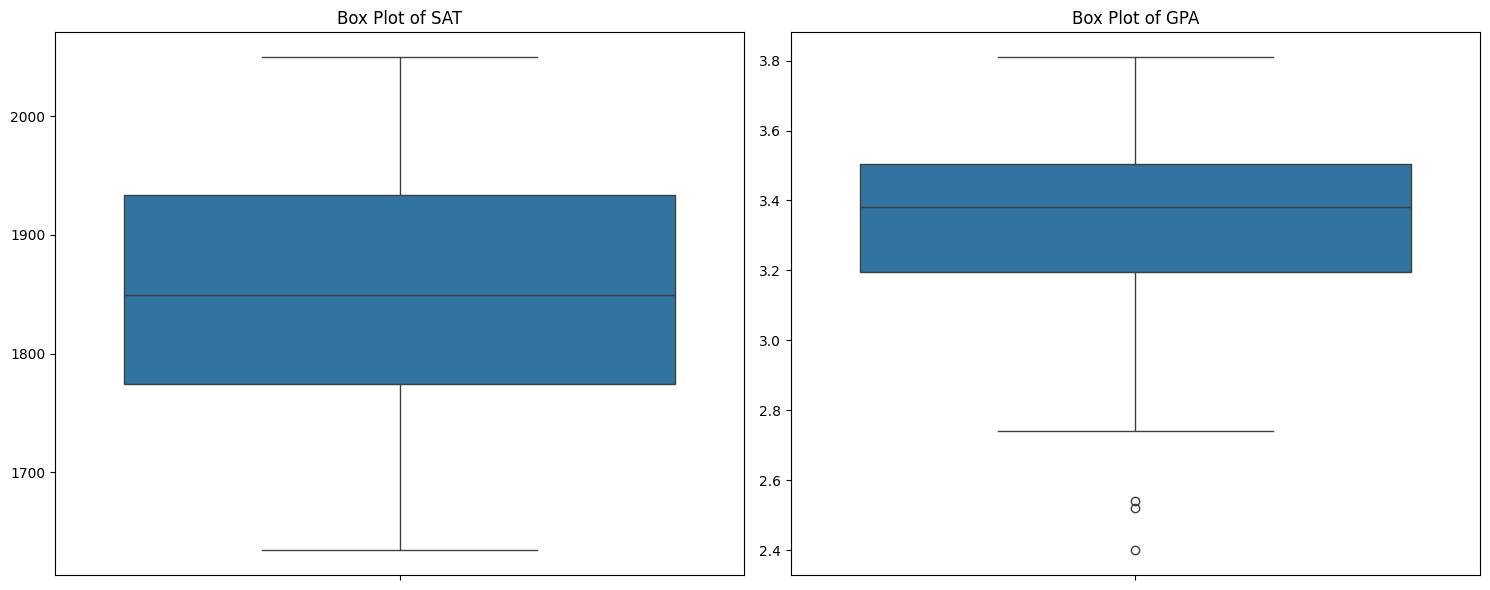

In [12]:
numerical_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(15, 6))
for i, column in enumerate(numerical_cols, 1):
    plt.subplot(1, len(numerical_cols), i)
    sns.boxplot(y=df[column])
    plt.title(f'Box Plot of {column}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [13]:
# Calculate IQR for 'SAT'
Q1_sat = df['SAT'].quantile(0.25)
Q3_sat = df['SAT'].quantile(0.75)
IQR_sat = Q3_sat - Q1_sat

# Define bounds for 'SAT' outliers
lower_bound_sat = Q1_sat - 1.5 * IQR_sat
upper_bound_sat = Q3_sat + 1.5 * IQR_sat

# Calculate IQR for 'GPA'
Q1_gpa = df['GPA'].quantile(0.25)
Q3_gpa = df['GPA'].quantile(0.75)
IQR_gpa = Q3_gpa - Q1_gpa

# Define bounds for 'GPA' outliers
lower_bound_gpa = Q1_gpa - 1.5 * IQR_gpa
upper_bound_gpa = Q3_gpa + 1.5 * IQR_gpa

print(f"SAT Outlier Bounds: ({lower_bound_sat:.2f}, {upper_bound_sat:.2f})")
print(f"GPA Outlier Bounds: ({lower_bound_gpa:.2f}, {upper_bound_gpa:.2f})")

SAT Outlier Bounds: (1534.00, 2174.00)
GPA Outlier Bounds: (2.73, 3.97)


In [14]:
# Identify and remove outliers
df_no_outliers = df[
    (df['SAT'] >= lower_bound_sat) & (df['SAT'] <= upper_bound_sat) &
    (df['GPA'] >= lower_bound_gpa) & (df['GPA'] <= upper_bound_gpa)
]
print(f"Original DataFrame shape: {df.shape}")
print(f"DataFrame shape after outlier removal: {df_no_outliers.shape}")

# Assign the cleaned DataFrame back to df for subsequent steps
df = df_no_outliers.copy()

Original DataFrame shape: (83, 2)
DataFrame shape after outlier removal: (80, 2)


In [15]:
x = df.iloc[:, :-1]
print(f"Shape of x after cleaning: {x.shape}")

Shape of x after cleaning: (80, 1)


In [16]:
y = df.iloc[:, -1]
print(f"Shape of y after cleaning: {y.shape}")

Shape of y after cleaning: (80,)


In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Dataset is splitted for training and testing")

Dataset is splitted for training and testing


## 4. Modelling

### 4.1 Model Approach
Since there is only one predictor, a simple Linear Regression model was used to fit a straight line through `SAT` and `GPA`. Linear Regression is well suited here because it directly tests whether the relationship between test score and GPA is approximately proportional over the observed range, and the single-coefficient model is easy to interpret directly as GPA points gained per additional SAT point.

### 4.2 Model Training
The scikit-learn `LinearRegression` estimator was instantiated and fit on `x_train` and `y_train`. During `fit()`, the model estimates the single slope coefficient and the intercept that minimise the sum of squared residuals between actual and predicted GPA on the training data.

### 4.3 Model Outputs & Interpretation
The trained model produced a coefficient (slope) of 0.001394 and an intercept of 0.7916, giving the fitted equation `GPA ≈ 0.79 + 0.0014 × SAT`. This means a hypothetical student with a SAT score of 0 would be predicted a GPA of about 0.79 (outside the meaningful range of the data), and every additional 100 SAT points is associated with an increase of roughly 0.14 GPA points.

### Python Coding Required: Training the ML model

In [18]:
model = LinearRegression()
print("Model Created")

Model Created


In [19]:
model.fit(x_train, y_train)
print("Model is trained")

Model is trained


In [20]:
#Generate predictions for training and testing datasets using the trained model
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)
print("Predictions generated for both training and testing datasets")

Predictions generated for both training and testing datasets


## 5. Evaluation

### 5.1 Appropriate Metric Selection
As this is a regression problem, MAE, MSE, RMSE, and R² were used instead of classification metrics. MAE gives the average absolute error in GPA points, MSE and RMSE penalise larger errors more heavily (with RMSE expressed back in GPA points), and R² indicates the proportion of variance in `GPA` explained by `SAT` alone.

### 5.2 Interpretation
Training set: MAE = 0.1302, MSE = 0.0266, RMSE = 0.1632, R² = 0.4140.
Testing set: MAE = 0.1412, MSE = 0.0357, RMSE = 0.1889, R² = 0.2497.

An R² of about 0.41 on training and 0.25 on testing shows that `SAT` alone explains only a modest share — roughly a quarter to two-fifths — of the variance in `GPA`. This is a much weaker fit than a single-feature model would show on a purely mechanical relationship, and it is the expected outcome for real academic data: GPA is shaped by many factors beyond a single standardized test score (coursework, effort, attendance, course difficulty, etc.), so a wide unexplained residual is realistic rather than a modelling defect. The drop in R² from training (0.41) to testing (0.25) is a larger generalisation gap than would be seen with a strongly linear relationship, and is consistent with the small test set (16 rows) rather than necessarily indicating overfitting. An RMSE of roughly 0.16–0.19 GPA points is still small in absolute terms, but relative to the overall spread of GPA in the data it reflects that SAT score is only a partial predictor of academic performance.

### Python Coding Required: Calculating the evaluation metrics

In [21]:
#Metrics for training data
mae = mean_absolute_error(y_train, y_pred_train)
mse = mean_squared_error(y_train, y_pred_train)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_pred_train)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 0.13018500266240624
Mean Squared Error (MSE): 0.026640847684693332
Root MSE (RMSE): 0.16322024287659093
R2 Score: 0.4139658204194906


In [22]:
#Metrics for testing data
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_test)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 0.14119268176233501
Mean Squared Error (MSE): 0.035672158378373064
Root MSE (RMSE): 0.1888707451628575
R2 Score: 0.24974140891204266


In [23]:
model.coef_

array([0.00139422])

In [24]:
model.intercept_

np.float64(0.7915566028933285)

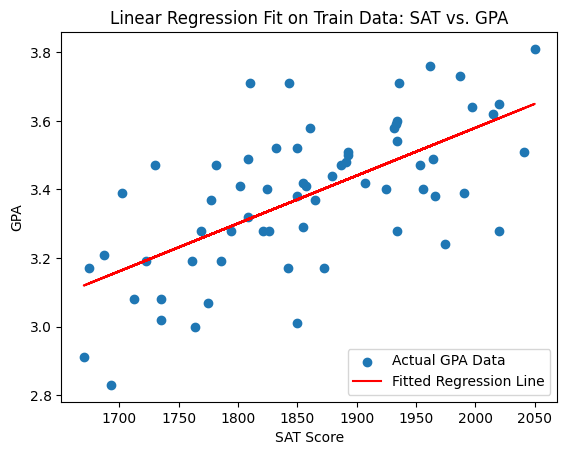

In [25]:
plt.scatter(x_train, y_train, label='Actual GPA Data')
plt.plot(x_train, y_pred_train, color='red', label='Fitted Regression Line')
plt.xlabel('SAT Score'); plt.ylabel('GPA')
plt.title('Linear Regression Fit on Train Data: SAT vs. GPA')
plt.legend()
plt.show()

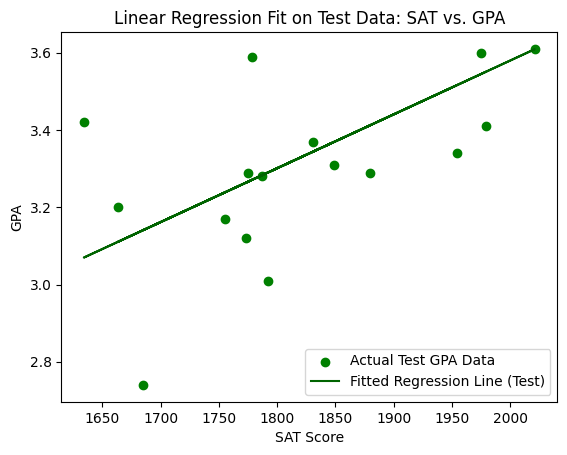

In [26]:
plt.scatter(x_test, y_test, label='Actual Test GPA Data', color='green')
plt.plot(x_test, y_pred_test, color='darkgreen', label='Fitted Regression Line (Test)')
plt.xlabel('SAT Score'); plt.ylabel('GPA')
plt.title('Linear Regression Fit on Test Data: SAT vs. GPA')
plt.legend()
plt.show()

## 6. Conclusion

### 6.1 Summary of Results
A simple Linear Regression model was built to predict `GPA` from `SAT` score alone. After removing 17 duplicate rows and 3 additional low-GPA outliers flagged by the IQR method, the model was trained on an 80:20 split and achieved R² ≈ 0.41 on training and R² ≈ 0.25 on testing, with RMSE around 0.16–0.19 GPA points — a modest result from a single predictor.

### 6.2 Key Insights
- `SAT` score by itself is only a partial predictor of `GPA`, explaining roughly a quarter to two-fifths of the variance without any other features.
- The fitted equation (`GPA ≈ 0.79 + 0.0014 × SAT`) gives a directly interpretable rule of thumb: every additional 100 SAT points is associated with about 0.14 additional GPA points.
- The raw dataset contained a meaningful proportion of duplicate rows (17 of 100, 17%), and a small cluster of low-GPA values flagged as IQR outliers — both worth checking before training any model.

### 6.3 Limitations & Future Work
- GPA is bounded between 0 and 4, so at the extremes the true relationship may flatten out in ways a straight line cannot capture.
- Only one feature was available; real GPA outcomes also depend on factors such as attendance, study habits, course difficulty, and extracurricular commitments, none of which are captured here.
- Future work could collect additional features for a multi-variable model, test whether removing the flagged GPA outliers changes the coefficient materially, and use cross-validation for a more robust performance estimate given the small sample size.

## 7. Appendix

### 7.1 Plots
- Box plots of `SAT` and `GPA` used for outlier inspection.
- Scatter plot with fitted regression line on the training data — SAT vs. GPA.
- Scatter plot with fitted regression line on the testing data — SAT vs. GPA.

### 7.2 Tables
- Summary statistics table (`df.describe()`) — reported under Data Understanding.
- First 5 rows of the dataset (`df.head()`) — reported under Data Understanding.

### 7.3 Python Code Snippets
All code snippets used in this experiment are reproduced in-line within the relevant sections above (Data Understanding, Data Preparation, Modelling, and Evaluation).